# Doble desventaja digital y contexto docente
Jose Guillermo Ticona Lipa

Pregunta: ¿coinciden ausencia de conexión doméstica y ratio territorial alto con mayor desfase de edad y grado? Se conserva una hipótesis refutable; no se asume causalidad. Corte 2025 del panel ENAHO e integración ESCALE. Semilla 42.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/datos.py').is_file())
sys.path.insert(0, str(ROOT/'src'))
import pandas as pd
from IPython.display import display, Image
from datos import construir
from analisis import cargar, entrenar, perfiles, doble_desventaja, explicar
R = ROOT/'resultados'
print('Python', sys.version.split()[0])

Python 3.12.14


## 1 Integración desde fuentes seleccionadas
Las tablas de entrada contienen códigos originales 2025. Las llaves se preservan como texto y se validan cardinalidades. El diccionario distingue 0/1 en selección múltiple y 1/2 en preguntas sí/no. No se rellena la respuesta desconocida con no.

In [2]:
df = construir()
display(pd.read_csv(R/'flujo_poblacion.csv'))
display(df.head())
print('Internet doméstico', df.internet_hogar.value_counts(dropna=False).to_dict())

{
  "servicios_primaria_secundaria_activos": 54038,
  "locales_vinculados": 54038,
  "geocodigos_discrepantes": 1,
  "fechas_padron": {
    "29-10-2025": 54038
  },
  "altitud": "No disponible en Padron ni Padlocal suministrados; no se fabrica.",
  "unidad": "Servicios activos B0/F0; contexto del distrito y area, no escuela de cada estudiante.",
  "filas": 19286,
  "columnas": 37,
  "conglomerados": 4701,
  "distritos": 1186,
  "cobertura_contexto": 0.9808669501192575,
  "prevalencia_rezago": 0.377216633827647,
  "prevalencia_atraso_dos_anios": 0.04350305921393757,
  "fechas_nacimiento_disponibles": 0,
  "cruces": {
    "cruce_educacion": {
      "both": 19286,
      "left_only": 0,
      "right_only": 0
    },
    "cruce_hogar": {
      "both": 19286,
      "left_only": 0,
      "right_only": 0
    },
    "cruce_sumaria": {
      "both": 19286,
      "left_only": 0,
      "right_only": 0
    }
  }
}
Internet doméstico {1.0: 18456, 0.0: 830}


,etapa,n
0,Personas con identificacion 2025,115145
1,Edad de 6 a 17 anos,24195
2,Residentes habituales,23345
3,Matriculados primaria/secundaria con grado valido,19286


,conglome,vivienda,hogar,codperso,ubigeo,edad,grado_acumulado,edad_normativa,anios_desfase,rezago,atraso_dos_anios,mujer,rural,lengua,lengua_originaria,dominio,electricidad,internet_hogar,uso_internet,frecuencia_tic,pobreza,miembros_hogar,ingreso_pc_mensual,gasto_pc_mensual,log_ingreso_pc,log_gasto_pc,FACTOR07,FACPOB07,escuelas,proporcion_publica,alumnos,docentes,latitud,longitud,servicios_con_conteos,ratio_alumno_docente,contexto_encontrado
0,015001,113,11,03,010101,16,11.0,16.0,0.0,0,0,1.0,0.0,4,0.0,4,1.0,1.0,1.0,3.0,3,4,2186.471191,1374.476725,7.690501,7.226556,184.864182,184.864182,24.0,0.833333,8276.0,482.0,-6.227534,-77.869223,24.0,17.170124,1
1,015001,130,11,03,010101,9,4.0,9.0,0.0,0,0,0.0,0.0,4,0.0,4,1.0,1.0,0.0,0.0,3,3,2288.267795,1379.084418,7.735987,7.229900,184.864182,184.864182,24.0,0.833333,8276.0,482.0,-6.227534,-77.869223,24.0,17.170124,1
2,015001,113,11,04,010101,13,8.0,13.0,0.0,0,0,1.0,0.0,4,0.0,4,1.0,1.0,1.0,3.0,3,4,2186.471191,1374.476725,7.690501,7.226556,184.864182,184.864182,24.0,0.833333,8276.0,482.0,-6.227534,-77.869223,24.0,17.170124,1
3,015003,116,11,04,010101,9,3.0,8.0,1.0,1,0,1.0,0.0,4,0.0,4,1.0,1.0,1.0,3.0,3,4,519.833333,854.691976,6.255430,6.751910,84.890594,84.890594,24.0,0.833333,8276.0,482.0,-6.227534,-77.869223,24.0,17.170124,1
4,015003,144,11,04,010101,12,7.0,12.0,0.0,0,0,0.0,0.0,4,0.0,4,1.0,1.0,1.0,3.0,3,4,2667.250000,1785.010579,7.889178,7.487740,84.890594,84.890594,24.0,0.833333,8276.0,482.0,-6.227534,-77.869223,24.0,17.170124,1


## 2 Clasificación y prueba independiente
Se excluyen edad, grado y toda variable que construye la etiqueta. Pipeline se ajusta dentro de cada fold. Test no selecciona modelos, hiperparámetros ni umbral. Se conserva una sensibilidad de atraso de dos años y otra separación por distrito.

Logistica {'C': 0.1} AP CV 0.4121
Logistica {'C': 1.0} AP CV 0.4101
RandomForest {'min_samples_leaf': 5} AP CV 0.409
RandomForest {'min_samples_leaf': 20} AP CV 0.4121
XGBoost {'max_depth': 2} AP CV 0.4138
XGBoost {'max_depth': 4} AP CV 0.4056
LightGBM {'num_leaves': 7} AP CV 0.4077
LightGBM {'num_leaves': 15} AP CV 0.4029
{
  "ganador": "XGBoost",
  "criterio": "Mayor AP media en validacion GroupKFold de train; test no elige modelo ni parametros.",
  "n_train": 15498,
  "n_test": 3788,
  "conglomerados_train": 3760,
  "conglomerados_test": 941,
  "solapamiento": 0,
  "prevalencia_test": 0.38595564941921856,
  "test": {
    "ROC_AUC": 0.5397024123892993,
    "PR_AUC_AP": 0.416418867717058,
    "F1_macro": 0.521912206440645,
    "Brier": 0.24803540110588074
  },
  "IC95_bootstrap_conglomerados": {
    "ROC_AUC": [
      0.5159198863907369,
      0.5631786335292157
    ],
    "PR_AUC_AP": [
      0.3884090452421745,
      0.4449993667061361
    ],
    "F1_macro": [
      0.50319774599678

,modelo,parametros,CV_ROC_AUC,CV_PR_AUC_AP,CV_F1_macro,CV_Brier,CV_AP_sd
0,XGBoost,"{""max_depth"": 2}",0.540603,0.413764,0.517488,0.248508,0.018031
1,RandomForest,"{""min_samples_leaf"": 20}",0.537887,0.412097,0.517935,0.247965,0.018219
2,Logistica,"{""C"": 0.1}",0.542257,0.412083,0.519794,0.248880,0.014920
3,LightGBM,"{""num_leaves"": 7}",0.534144,0.407665,0.515586,0.249254,0.015508


,modelo,ROC_AUC,PR_AUC_AP,F1_macro,Brier
0,Logistica,0.539652,0.426940,0.519519,0.247980
1,RandomForest,0.538502,0.412260,0.528579,0.247801
2,XGBoost,0.539702,0.416419,0.521912,0.248035
3,LightGBM,0.542792,0.418268,0.527983,0.248092


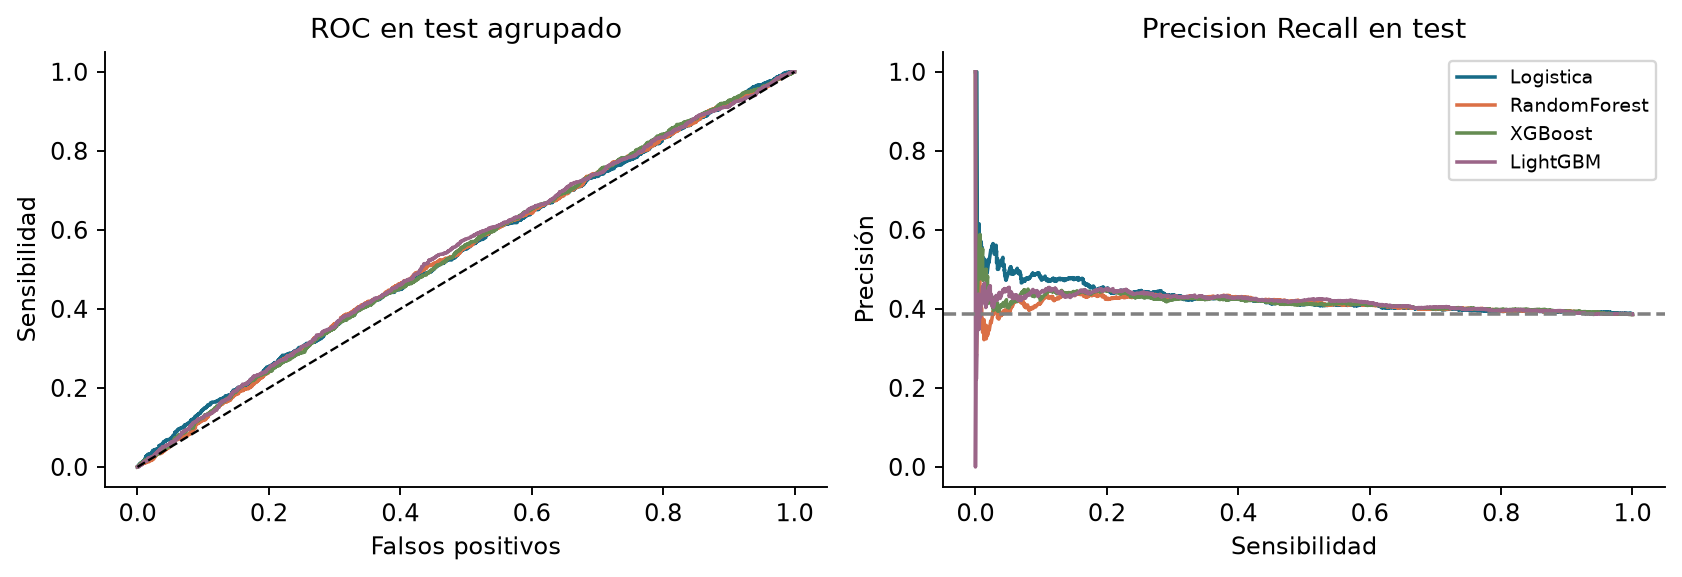

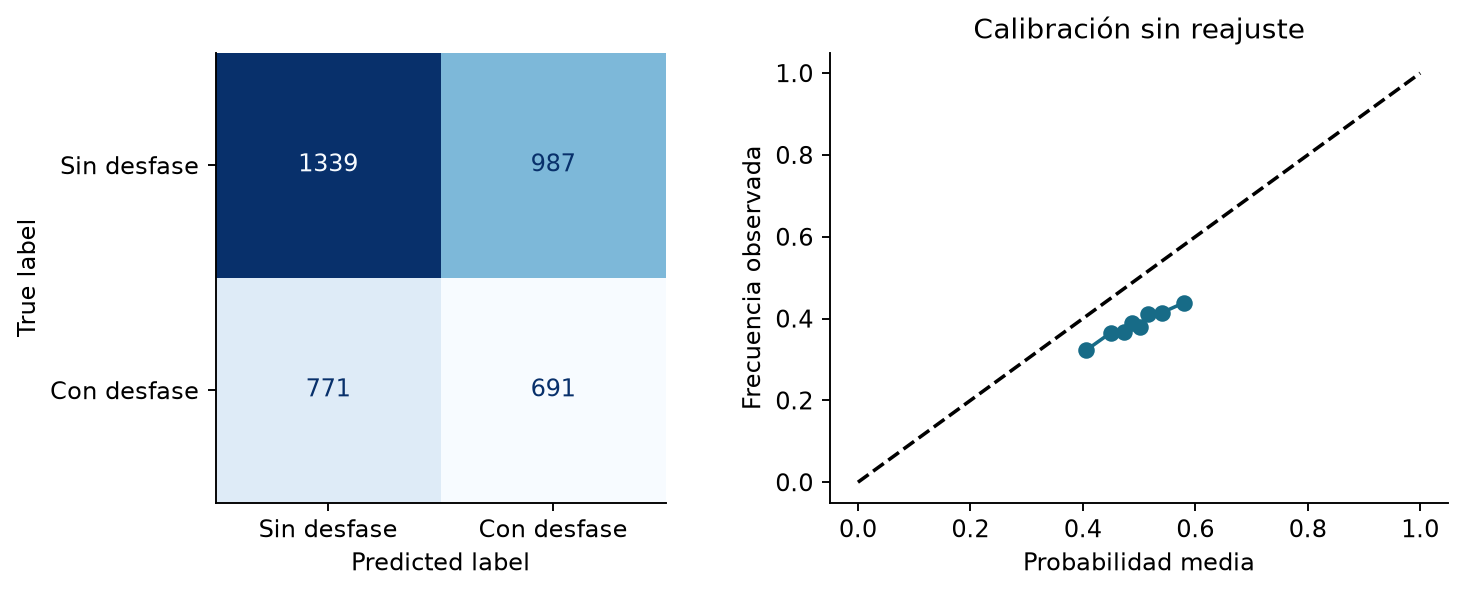

In [3]:
tr, te, modelo = entrenar(df)
display(pd.read_csv(R/'comparacion_validacion.csv'))
display(pd.read_csv(R/'comparacion_test.csv'))
display(Image(filename=str(R/'figuras/roc_pr.png')))
display(Image(filename=str(R/'figuras/confusion_calibracion.png')))

## 3 Perfiles de recursos
Se comparan K-Means y GMM. La selección se realiza sobre train. El desfase caracteriza los perfiles principales después de construirlos. La versión que incorpora desfase se reporta como sensibilidad separada.

,algoritmo,k,silueta,Davies_Bouldin,Calinski_Harabasz
0,GMM,6,0.356671,1.065590,538.087818
1,KMeans,6,0.355723,1.062413,543.949412
2,KMeans,5,0.343735,1.180319,548.196225
3,GMM,5,0.341832,1.163852,531.006679
4,KMeans,4,0.325150,1.236566,558.661985
5,KMeans,2,0.315042,1.441668,733.630500
6,GMM,2,0.308080,1.514250,671.145239
7,GMM,3,0.307039,1.388974,598.169638
8,KMeans,3,0.304659,1.394607,604.430385
9,GMM,4,0.163697,2.878290,409.277760


,cluster,rural,electricidad,internet_hogar,uso_internet,frecuencia_tic,log_ingreso_pc,log_gasto_pc,miembros_hogar,ratio_alumno_docente,proporcion_publica,rezago,atraso_dos_anios,anios_desfase,n,nombre
0,0,1.000000,1.000000,1.0,0.000000,0.000000,5.968812,5.897960,4.967532,10.175579,0.993524,0.327381,0.032468,0.369048,1848,Rural con conexión mayoritaria y ratio docente...
1,1,0.000000,1.000000,1.0,1.000000,2.835832,6.691330,6.555688,4.716733,17.476653,0.489148,0.374121,0.038442,0.424085,9807,Urbano con conexión mayoritaria y ratio docent...
2,2,0.864583,0.000000,1.0,0.467803,1.204545,5.921949,5.875010,5.500947,11.980042,0.936449,0.432765,0.081439,0.531250,1056,Rural con conexión mayoritaria y ratio docente...
3,3,1.000000,1.000000,1.0,1.000000,2.698132,6.195921,6.107215,4.693252,10.361708,0.991941,0.408254,0.046849,0.468210,3586,Rural con conexión mayoritaria y ratio docente...
4,4,0.660241,0.608434,0.0,0.386747,1.031325,5.898140,5.944899,5.124096,14.053581,0.833111,0.418072,0.089157,0.543373,830,Rural con baja conexión y ratio docente 14.1
5,5,0.000000,1.000000,1.0,0.000000,0.000000,6.423409,6.255728,5.021769,17.492595,0.539322,0.339509,0.034275,0.396480,2159,Urbano con conexión mayoritaria y ratio docent...


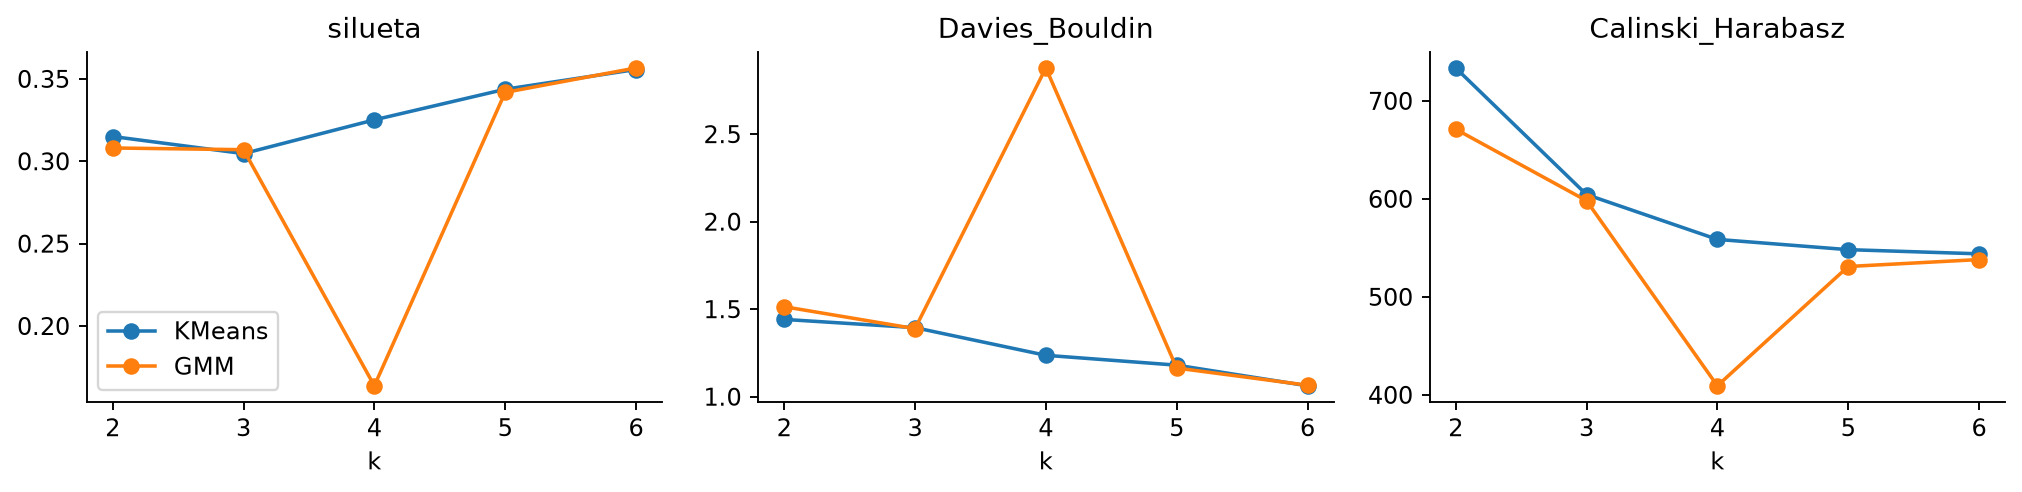

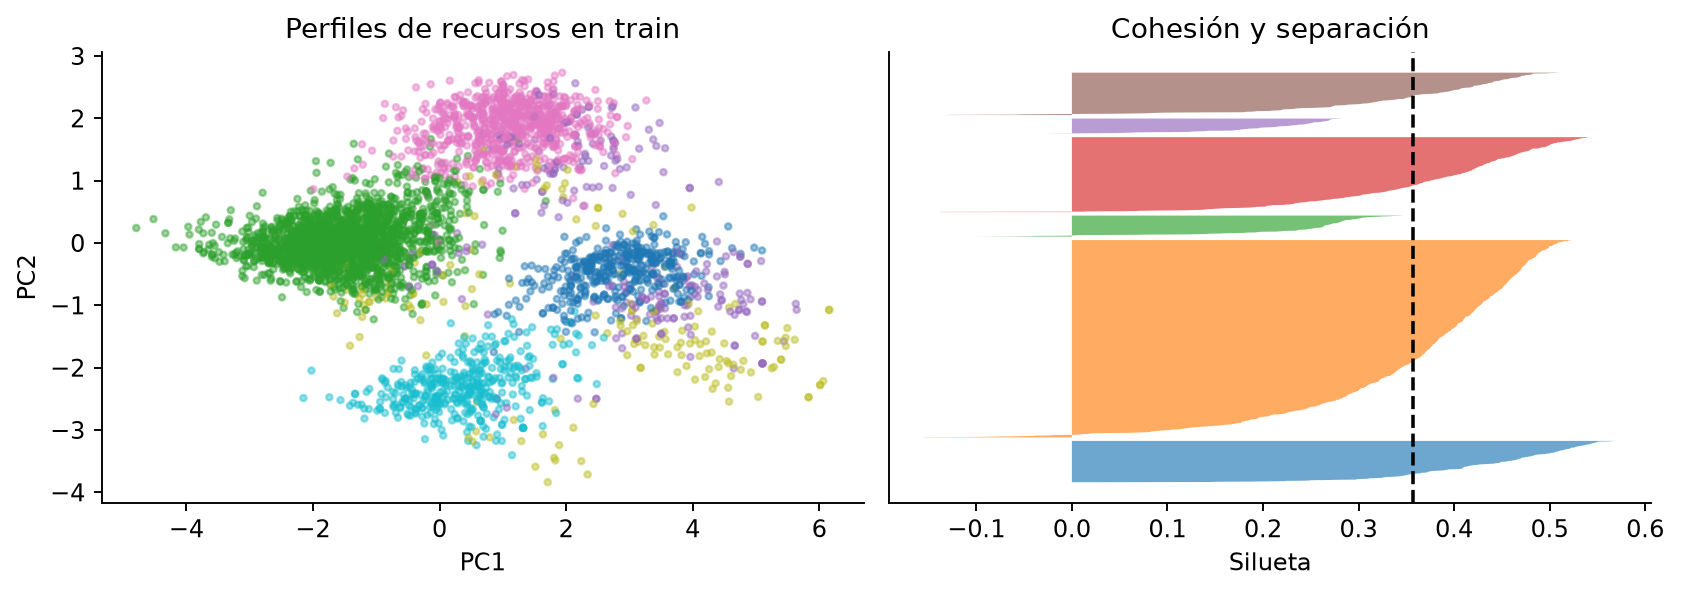

In [4]:
labels = perfiles(df, tr, te)
display(pd.read_csv(R/'comparacion_clustering.csv'))
display(pd.read_csv(R/'perfiles_clusters.csv'))
display(Image(filename=str(R/'figuras/seleccion_clusters.png')))
display(Image(filename=str(R/'figuras/pca_siluetas.png')))

## 4 Cruce de desventajas
El percentil 75 del ratio se fija en train. Las cuatro celdas se describen en test; no se considera carga real del aula ni efecto causal. Revisar tamaños e intervalos antes de interpretar tasas.

{
  "umbral_ratio_train_P75": 18.363013698630137,
  "contraste_aditivo_test": 0.15961199552143968,
  "interpretacion": "Contraste descriptivo de cuatro tasas crudas; no estima efecto causal ni interaccion ajustada. Ratio alto significa P75 de la muestra train, no norma MINEDU.",
  "casos_sin_desfase_doble_desventaja_test": 10,
  "IC95_contraste_bootstrap_conglomerados": [
    -0.043388639652212416,
    0.35255623604553493
  ],
  "replicas_validas": 1000
}
{
  "umbral_ratio_train_P75": 18.363013698630137,
  "contraste_aditivo_test": 0.15961199552143968,
  "interpretacion": "Contraste descriptivo de cuatro tasas crudas; no estima efecto causal ni interaccion ajustada. Ratio alto significa P75 de la muestra train, no norma MINEDU.",
  "casos_sin_desfase_doble_desventaja_test": 10,
  "IC95_contraste_bootstrap_conglomerados": [
    -0.043388639652212416,
    0.35255623604553493
  ],
  "replicas_validas": 1000
}


,particion,grupo,n,conglomerados,tasa_rezago,tasa_atraso_2,sin_desfase,IC95_inf,IC95_sup
0,train,0,10874,2786,0.367942,0.039636,6873,0.356536,0.379847
1,train,1,3684,871,0.391151,0.045331,2243,0.371132,0.411589
2,train,2,528,221,0.418561,0.092803,307,0.372374,0.468487
3,train,3,128,65,0.351562,0.070312,83,0.249947,0.443735
4,test,0,2681,700,0.386796,0.042521,1644,0.364377,0.411512
5,test,1,856,214,0.359813,0.044393,548,0.320622,0.403206
6,test,2,142,54,0.450704,0.077465,78,0.345173,0.541197
7,test,3,24,14,0.583333,0.208333,10,0.428571,0.750000


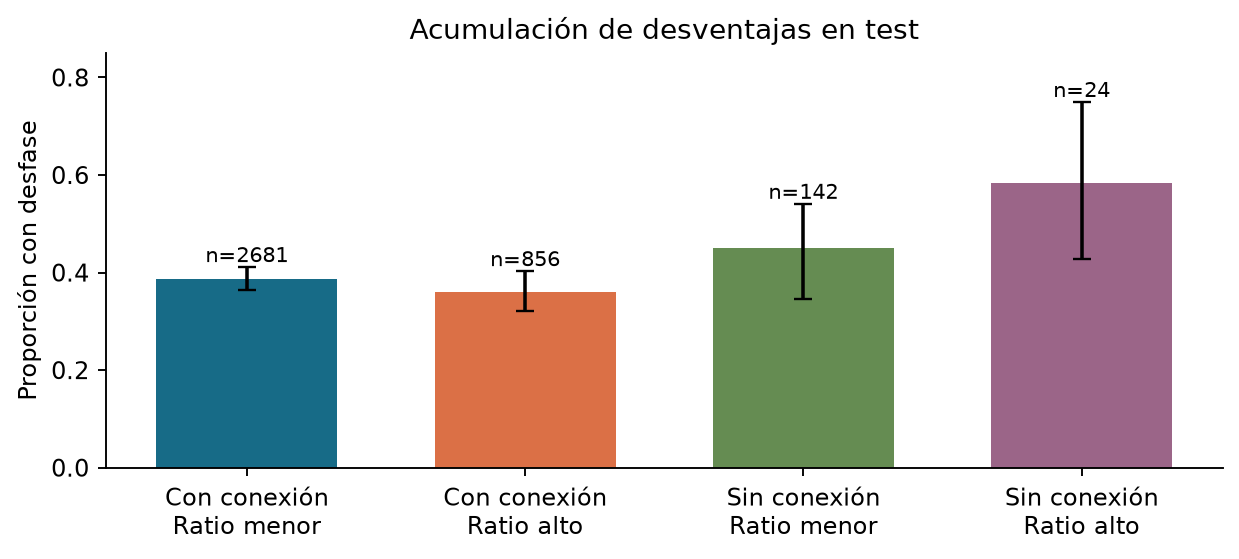

In [5]:
doble_desventaja(df,tr,te)
import runpy
_ = runpy.run_path(str(ROOT/'src/complementos.py'),run_name='__main__')
display(pd.read_csv(R/'doble_desventaja.csv'))
print((R/'resumen_desventaja.json').read_text(encoding='utf8'))
display(Image(filename=str(R/'figuras/doble_desventaja.png')))

## 5 Explicabilidad
Se toma el fondo solo de train. Beeswarm, dos dependencias y dos waterfall correctamente clasificados. Las contribuciones describen el modelo; no son efectos causales.

{
  "casos": {
    "alto": {
      "fila": 12936,
      "real": 1,
      "probabilidad": 0.622765064239502
    },
    "bajo": {
      "fila": 4139,
      "real": 0,
      "probabilidad": 0.3724721074104309
    }
  },
  "muestra": 350,
  "fondo_train": 80,
  "error_aditividad_max": 3.2224566137717403e-07,
  "nota": "Scatter coloreado describe dependencia; no calcula valores formales de interaccion ni causalidad."
}


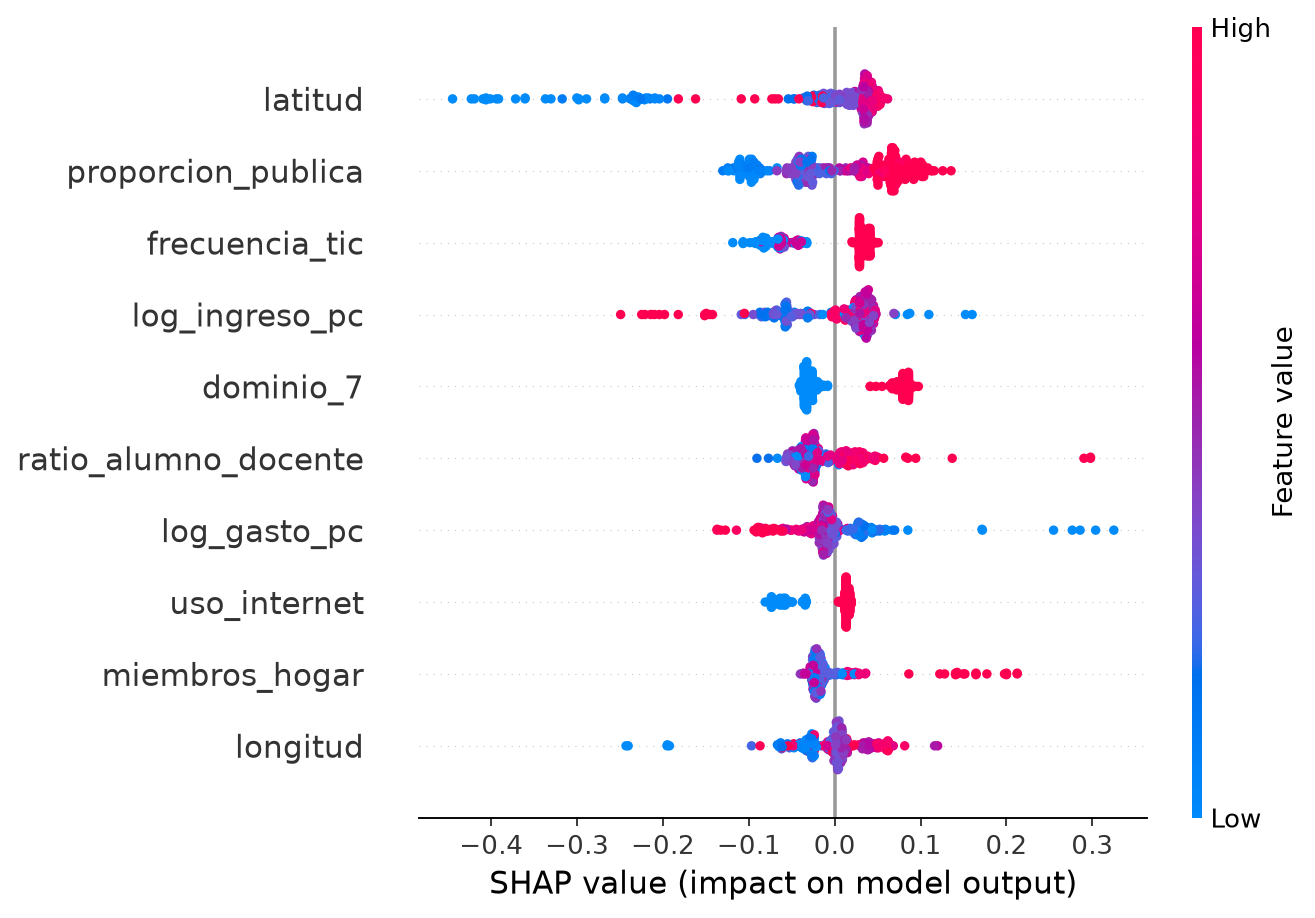

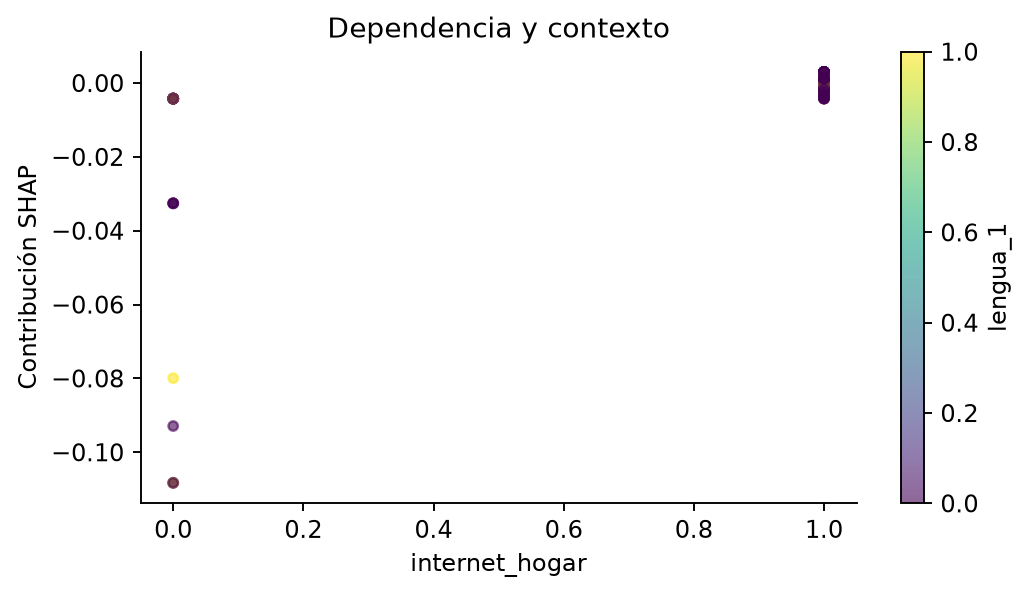

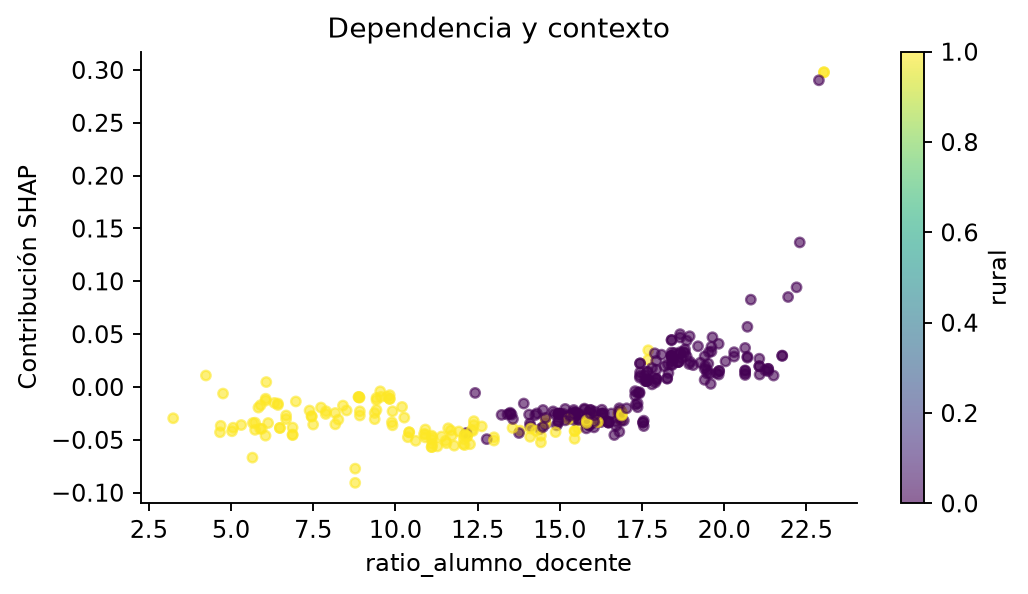

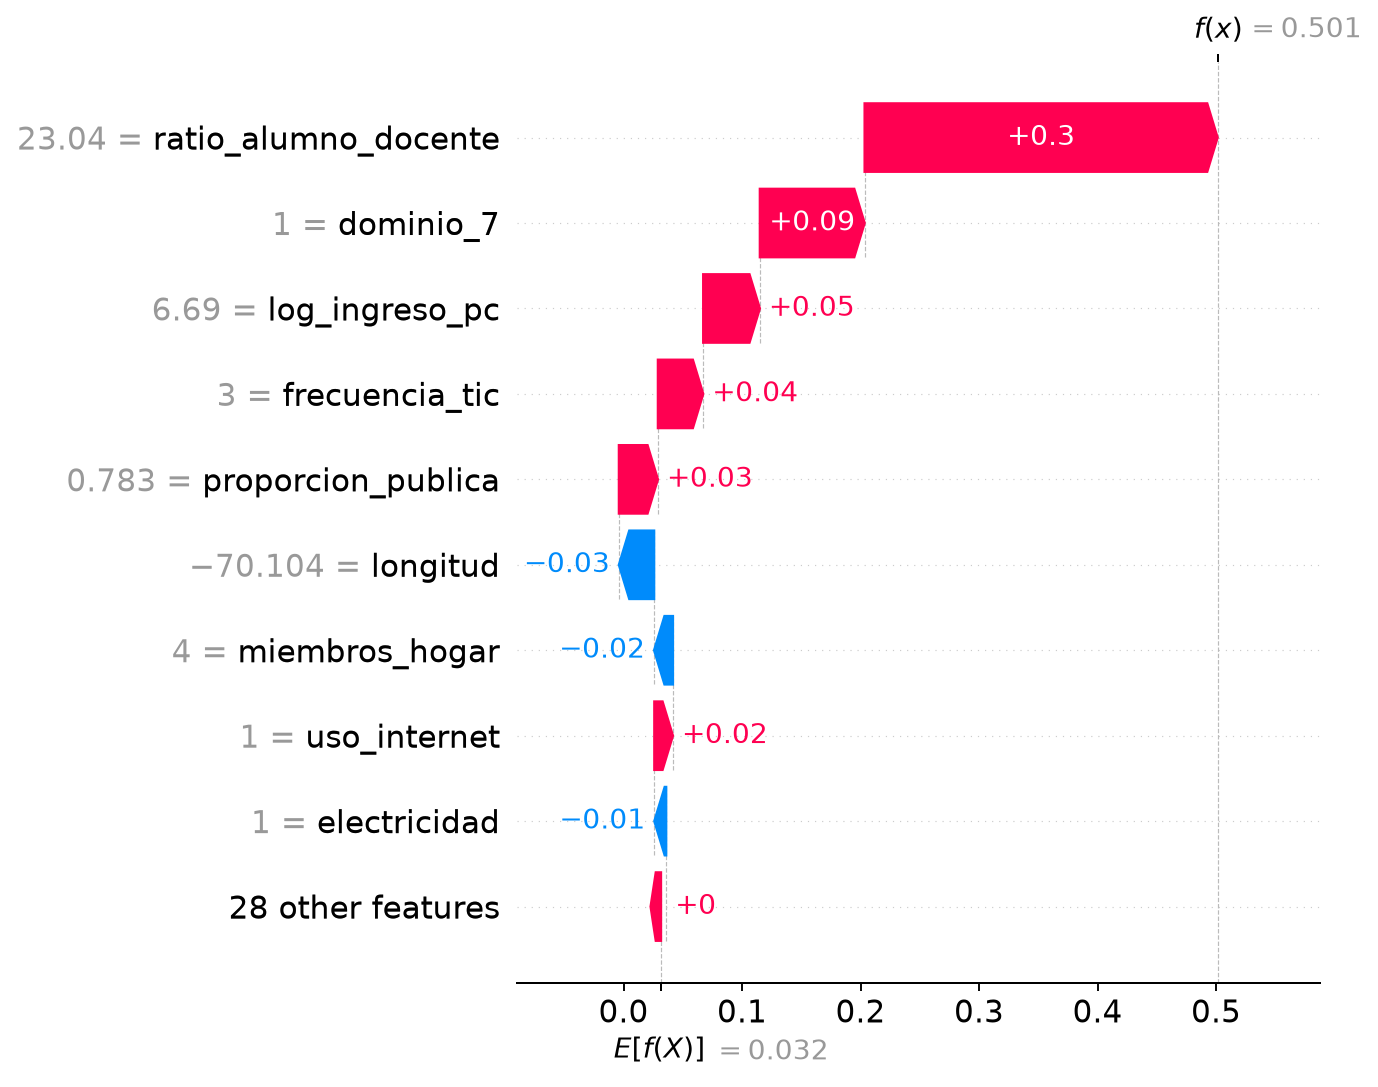

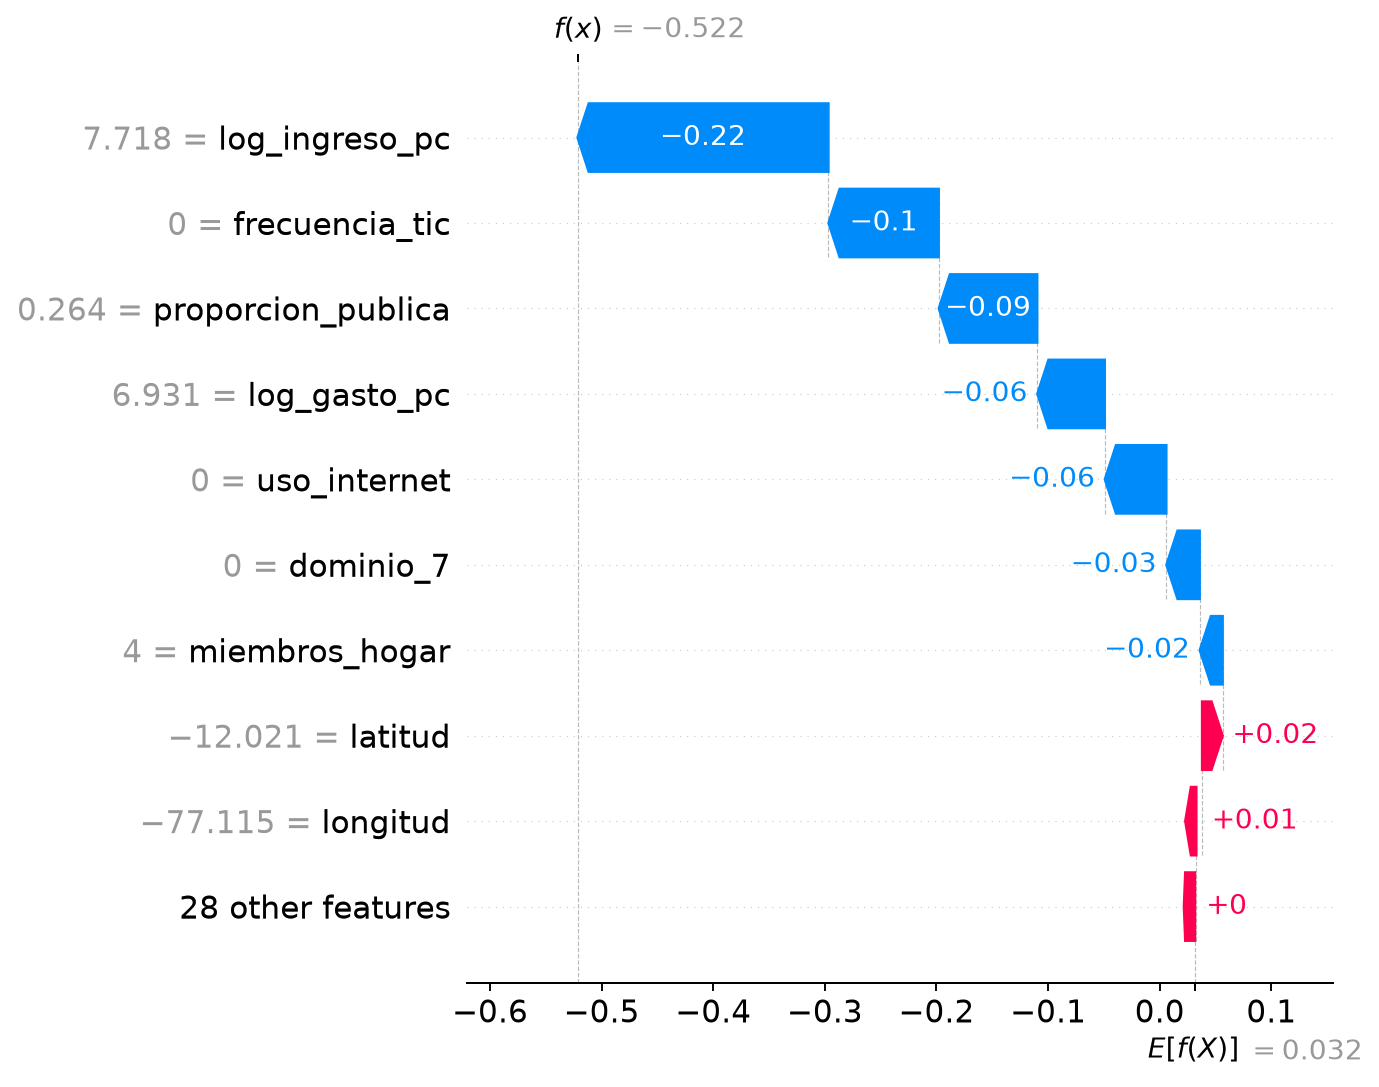

In [6]:
explicar(df,tr,te,modelo)
print((R/'resumen_shap.json').read_text(encoding='utf8'))
for name in ['shap_global','shap_dependencia_internet','shap_dependencia_ratio','shap_caso_alto','shap_caso_bajo']:
    display(Image(filename=str(R/'figuras'/f'{name}.png')))

## 6 Contratos de integridad y lectura de resultados
Verificar la partición, las fórmulas y la aditividad SHAP. Un AUC bajo es un resultado científico válido, pero impide afirmar que existe una buena herramienta de predicción. Los intervalos del contraste incluyen cero; los datos no confirman una interacción generalizable.

In [7]:
from verificar import verificar
checks = verificar()
print('Pruebas aprobadas:', len(checks))
print('Para regenerar el artículo editable: python src/generar_informe.py')

                                          prueba  cumple
                          Llave de persona unica    True
                          Poblacion entre 6 y 17    True
                Normativa derivada correctamente    True
             Etiqueta consistente con definicion    True
          No hay proxies directos en predictores    True
Todas las personas asignadas exactamente una vez    True
              Conglomerados train test disjuntos    True
                         Fold 1 sin solapamiento    True
                         Fold 2 sin solapamiento    True
                         Fold 3 sin solapamiento    True
                         Fold 4 sin solapamiento    True
                         Fold 5 sin solapamiento    True
                 Codigos binarios internet_hogar    True
                   Codigos binarios electricidad    True
                   Codigos binarios uso_internet    True
              Internet conserva ambas categorias    True
            Diccionario cubre t